# T4 Event displays: reference solution

Questions T4.1, T4.2, T4.3, T4.4, T4.5 of [TASKS.md](../../TASKS.md). The code is in the scripts named below (run from the repository root); this notebook runs them, shows their figures and gives the answers. Every number quoted comes from `results/`.

In [1]:
import os
from pathlib import Path

import IPython.display as ipd

here = Path.cwd()
os.chdir(next(p for p in (here, *here.parents) if (p / "pyproject.toml").exists()))  # the repository root
FIGURES = Path("solutions/stage1_flash/figures")


def show(*names):
    """Display the figures of a question (GIF animates, else the PNG)."""
    for name in names:
        path = next(p for p in (FIGURES / f"{name}.gif", FIGURES / f"{name}.png") if p.exists())
        ipd.display(ipd.Image(filename=str(path), width=900))


## Run the scripts

Data sets are generated on first use and cached in `solutions/stage1_flash/data/`.

In [2]:
!python solutions/stage1_flash/task4_event_displays.py
!python solutions/stage1_flash/task4_animation.py

T4.1 main event: Q = 557 p.e., barycentre 8.8 cm off
T4.4 straight        mean Q =  1019.5 +-  33.3 p.e.
T4.4 absorb          mean Q =   597.4 +-  24.6 p.e.
T4.4 absorb-scatter  mean Q =   567.7 +-  24.0 p.e.
T4.4 full            mean Q =   627.6 +-  25.1 p.e.
numbers -> ./solutions/stage1_flash/results/T4.json


T4.5: 280 photons, 74 detected, 163 frames (8.1 s), 1.03 MB -> ./solutions/stage1_flash/figures/t4_5_photons.gif; numbers -> ./solutions/stage1_flash/results/T4.json


## T4.1 Event display

The display shows the disc with its 32 identical sensors coloured by their charge (black = no light, grey, green =
most light), the true vertex (gold star) and the charge barycentre Σ n_j s_j / Σ n_j, the naive vertex estimate (red
cross). The barycentre is always pulled towards the centre, because it averages sensor positions on the wall and even
the far side of the ring collects light; the pull grows with r.

**Details**

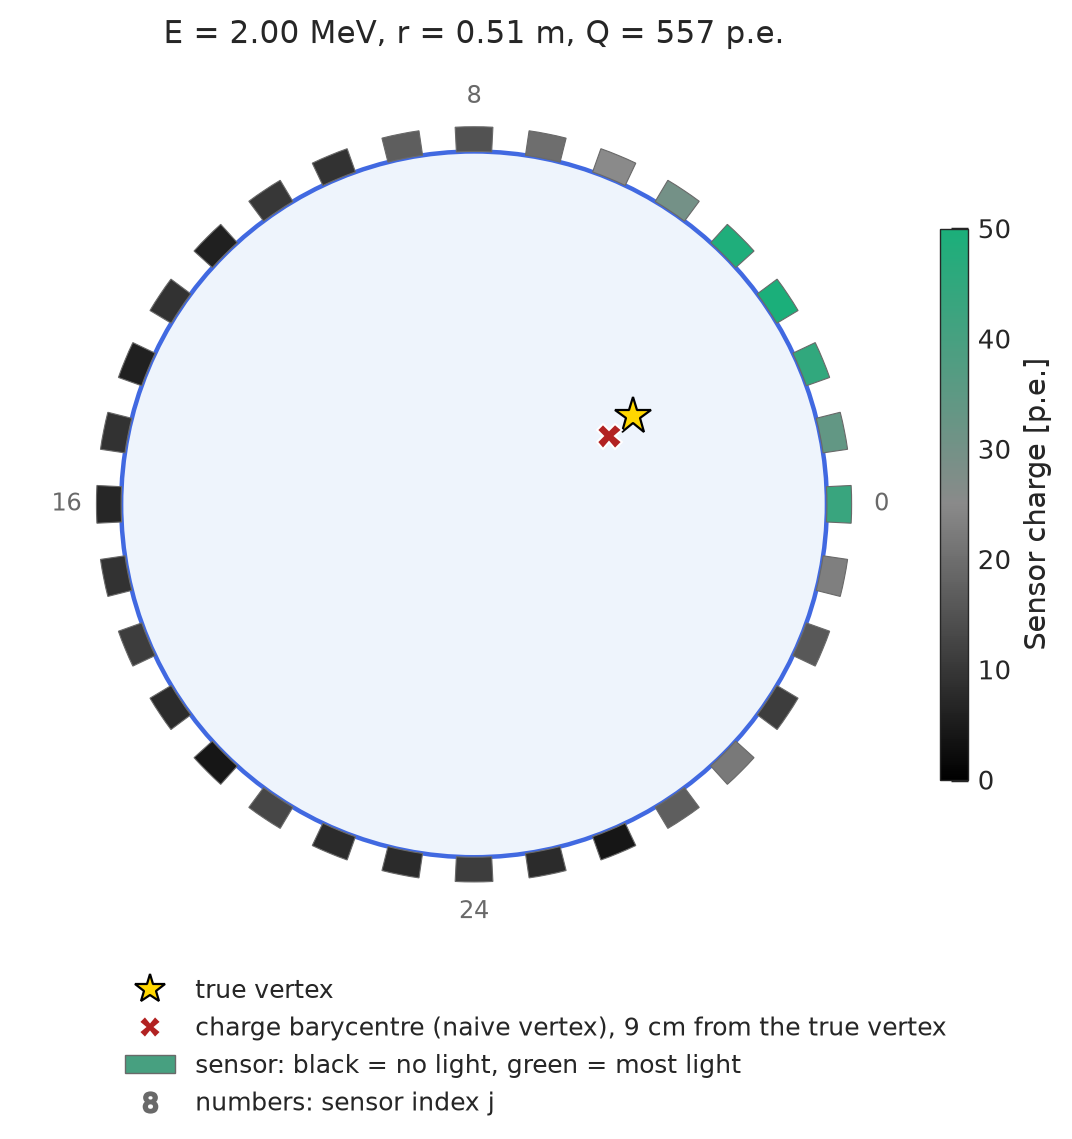

In [3]:
show("t4_1_event_display")

- *Main event* (E = 2.00 MeV, r = 0.51 m): 2083 emitted photons, Q = 557 p.e. (26.7 % collected); the brightest
  sensor (j = 3, 50 p.e.) faces the vertex; the barycentre sits at r = 0.43 m, 8.8 cm from the truth.

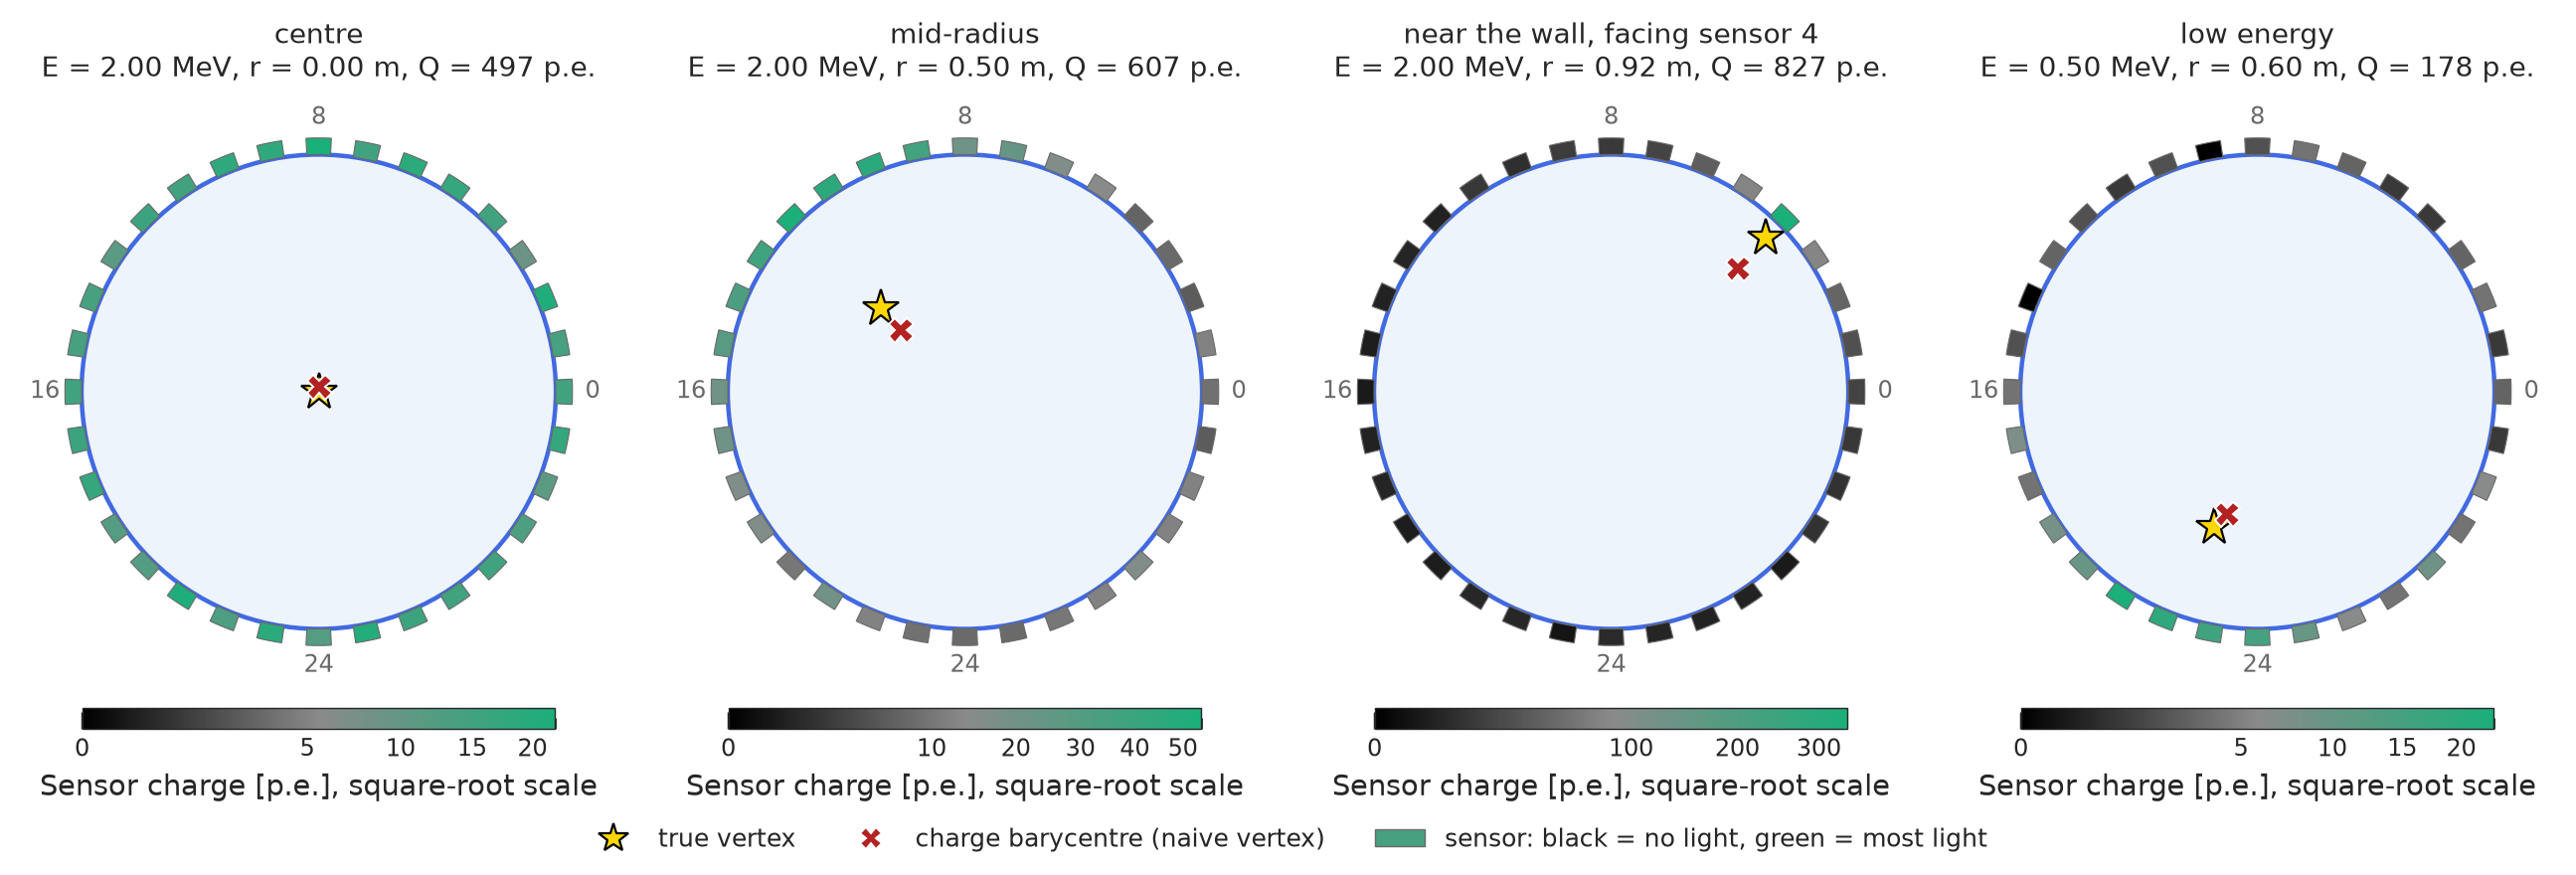

In [4]:
show("t4_1_gallery")

- *Gallery:* the pull is 2.0 cm at the centre (an almost uniform ring, Q = 497 p.e., brightest sensor 22 p.e.),
  12.5 cm at r = 0.50 m and 17.6 cm at r = 0.92 m, where the sensor facing the vertex alone collects 339 of the
  827 p.e. (41 %).
- The same 2 MeV gives more light near the wall (collected fraction 0.25 at the centre, 0.42 at r = 0.92 m in these
  single events); at the lowest energy of the prior (0.5 MeV, Q = 178 p.e.) two sensors are already empty.
- The gallery uses a square-root colour scale (stated on every colour bar) so that the dim sensors of the near-wall
  event remain visible next to the bright one.

*Figures:* `t4_1_event_display`, `t4_1_gallery` (`task4_event_displays.py`, drawing helpers in `event_display.py`).
*Numbers:* `results/T4.json` under `T4.1`.

## T4.2 Event display with timing

The event of T4.1 (t0 = 3 ns) as a charge display, a time display (sensors coloured by the relative mean time, royal
blue = early, peru = late) and as charge (bars on the colour scale of the display), mean time and first time per
sensor. Both times follow the distance to the sensor, i.e. the time of flight d_j / c_n; relative times are used
because t0 is unknown: it shifts every τ_j and τ̄ alike and cancels in τ_j − τ̄, the second half of `network_input`.

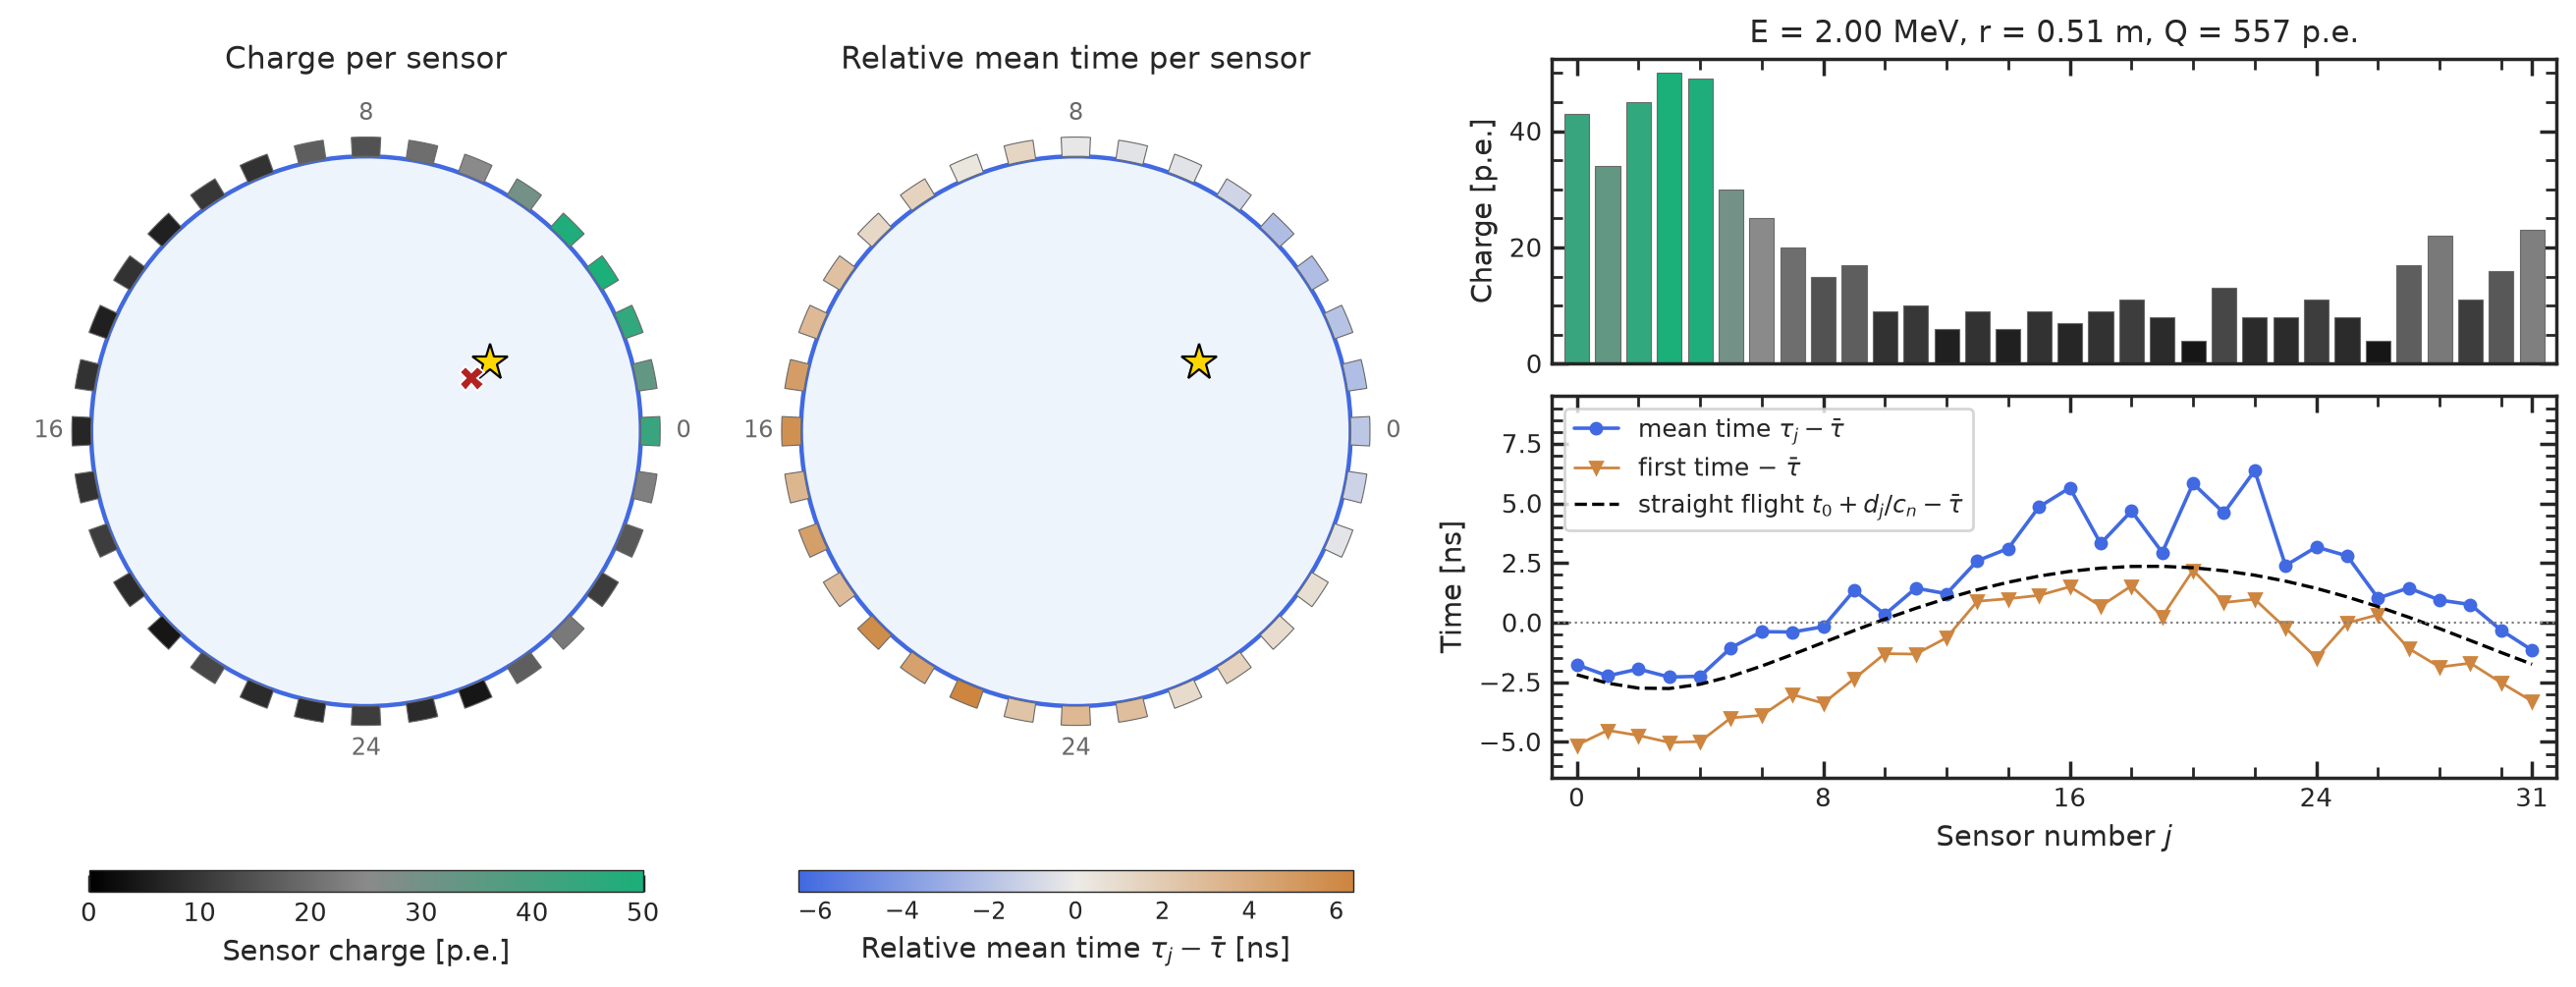

In [5]:
show("t4_2_timing")

**Details**

- *Nearest sensor* (j = 3, 0.49 m from the vertex): 2.28 ns early on average, its first photon 5.02 ns early, relative
  to the charge-weighted mean time τ̄ = 8.21 ns. *Farthest sensor* (j = 19, 1.51 m): 2.94 ns late (mean time), 0.26 ns
  late (first time).
- *Correlation with d_j:* 0.94 for the mean times, 0.96 for the first times (dashed straight-flight curve).
- *First hits* arrive a median 1.6 ns (0.1 to 2.95 ns) before the straight-flight time to the sensor centre, because
  each is the earliest of many photons smeared by the 1 ns jitter; the mean times of the far sensors lie above the
  curve, as those sensors receive relatively more delayed, scattered and reflected light.

*Figure:* `t4_2_timing` (`task4_event_displays.py`). *Numbers:* `results/T4.json` under `T4.2`.

## T4.3 Photon paths of one event

Of the 150 drawn photons of a 2 MeV event at r = 0.46 m, 39 are detected (peru, orange-brown, paths ending in a
diamond on a sensor), 90 are absorbed in the liquid (black crosses) and 21 by the wall between the sensors (black
triangles); along the paths there are 67 Rayleigh scatterings (indigo dots) and 16 wall reflections (teal squares).
Absorption dominates because the photons travel 0.86 m on average before their fate, not much less than λa = 1.5 m.

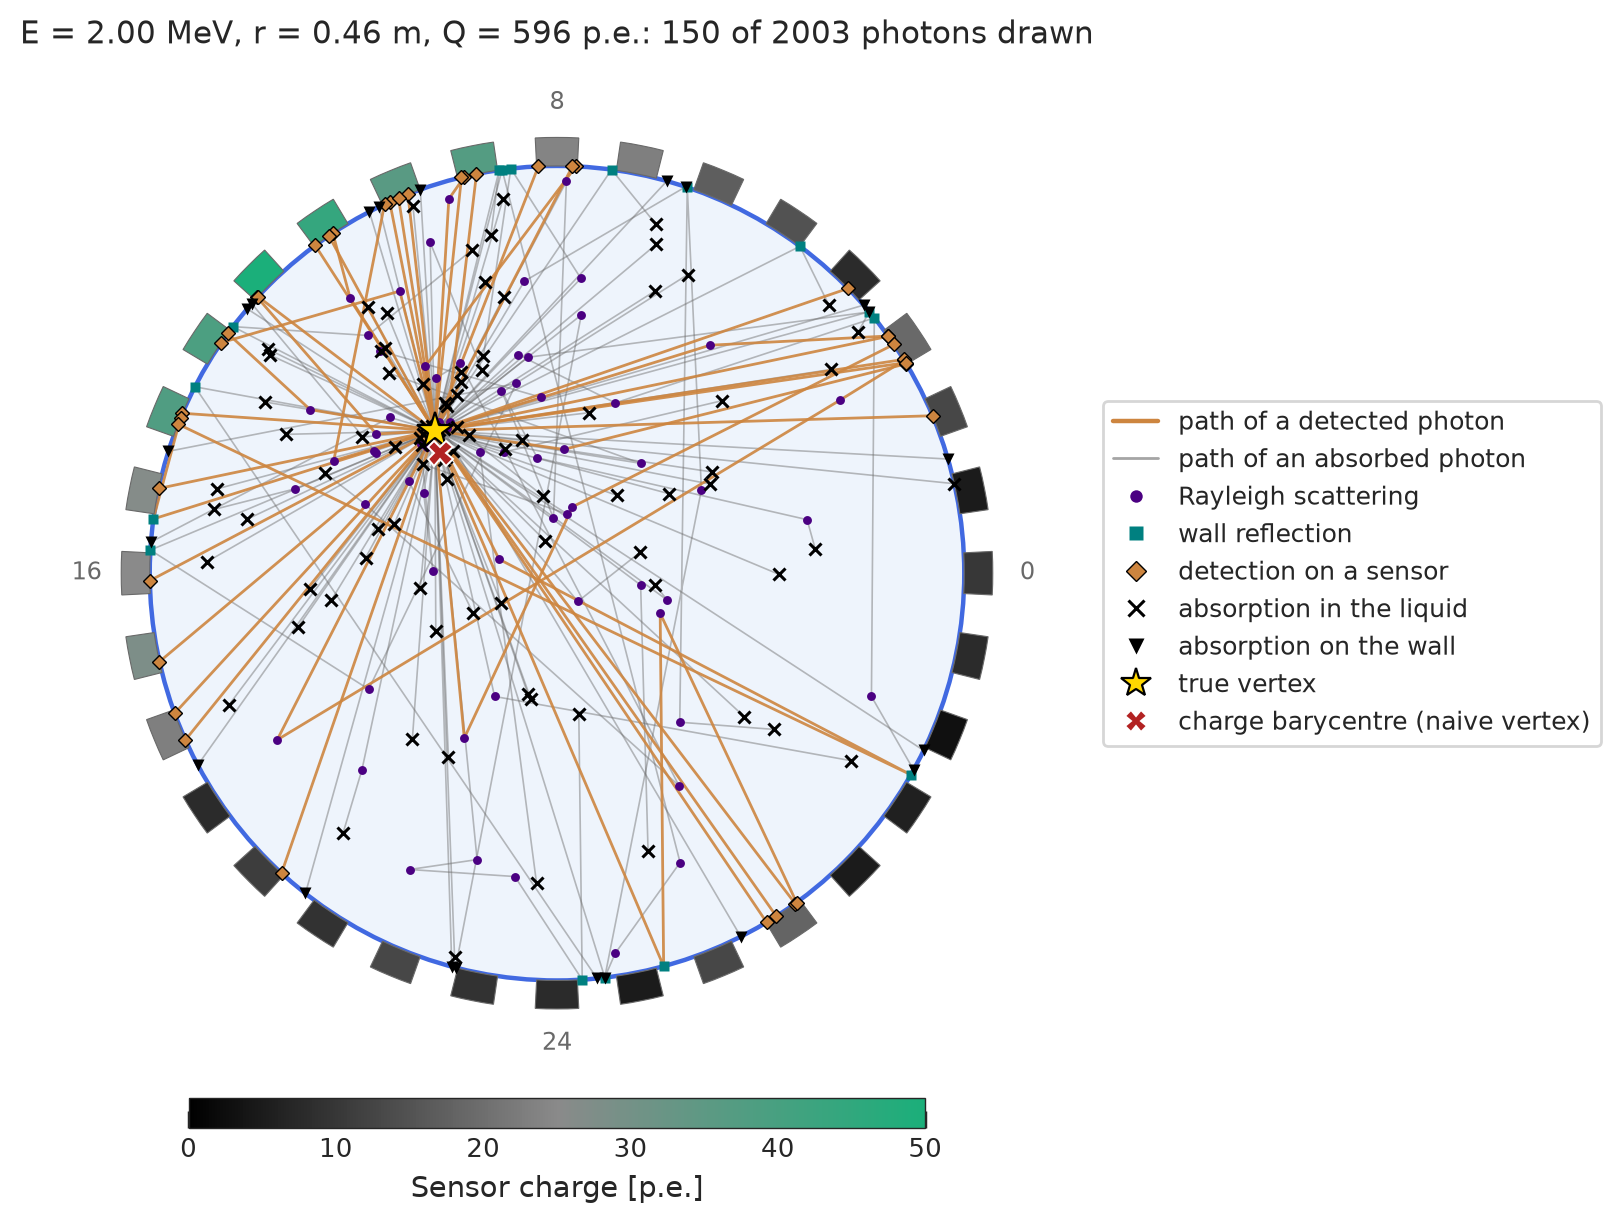

In [6]:
show("t4_3_photon_paths")

**Details**

- *Whole event:* 2003 photons emitted, Q = 596 p.e.: 29.8 % detected, 56.9 % absorbed in the liquid, 13.3 % absorbed
  by the wall, none lost; of the 596 detected photons 375 arrived directly, 160 after scattering and 61 after at least
  one reflection.
- *Path lengths:* mean 0.86 m, median 0.69 m before the fate.
- Scattering (λs = 2 m) kinks a minority of the paths; the reflections send light to sensors far from the vertex,
  which is why the far side of the ring is grey rather than black.
- Generated with `save_tracks=1, track_photons=150` (as `flashsim generate --save-tracks 1 --track-photons 150
  --fixed-vertex -0.3 0.35 --fixed-energy 2`); the paths are read back from `/tracks` of the HDF5 file.

*Figure:* `t4_3_photon_paths` (`task4_event_displays.py`). *Numbers:* `results/T4.json` under `T4.3`.

## T4.4 One theta, four presets

The same event (E = 2 MeV at r = 0.67 m) under the four presets: straight light collects 0.510 of the photons,
absorption reduces this to 0.299, scattering further to 0.284, and reflection gives some light back, 0.314.
Absorption sharpens the charge pattern (it punishes the long paths to the far side), reflection smooths it again; the
relative-time profiles keep the shape of the time of flight in every preset.

**Details** (`simulate(0.6, 0.3, 2.0, t0=0.0, config=preset(name), seed=10, save_tracks=1)`, the example call of
TASKS.md; profiles from 2000 events per preset)

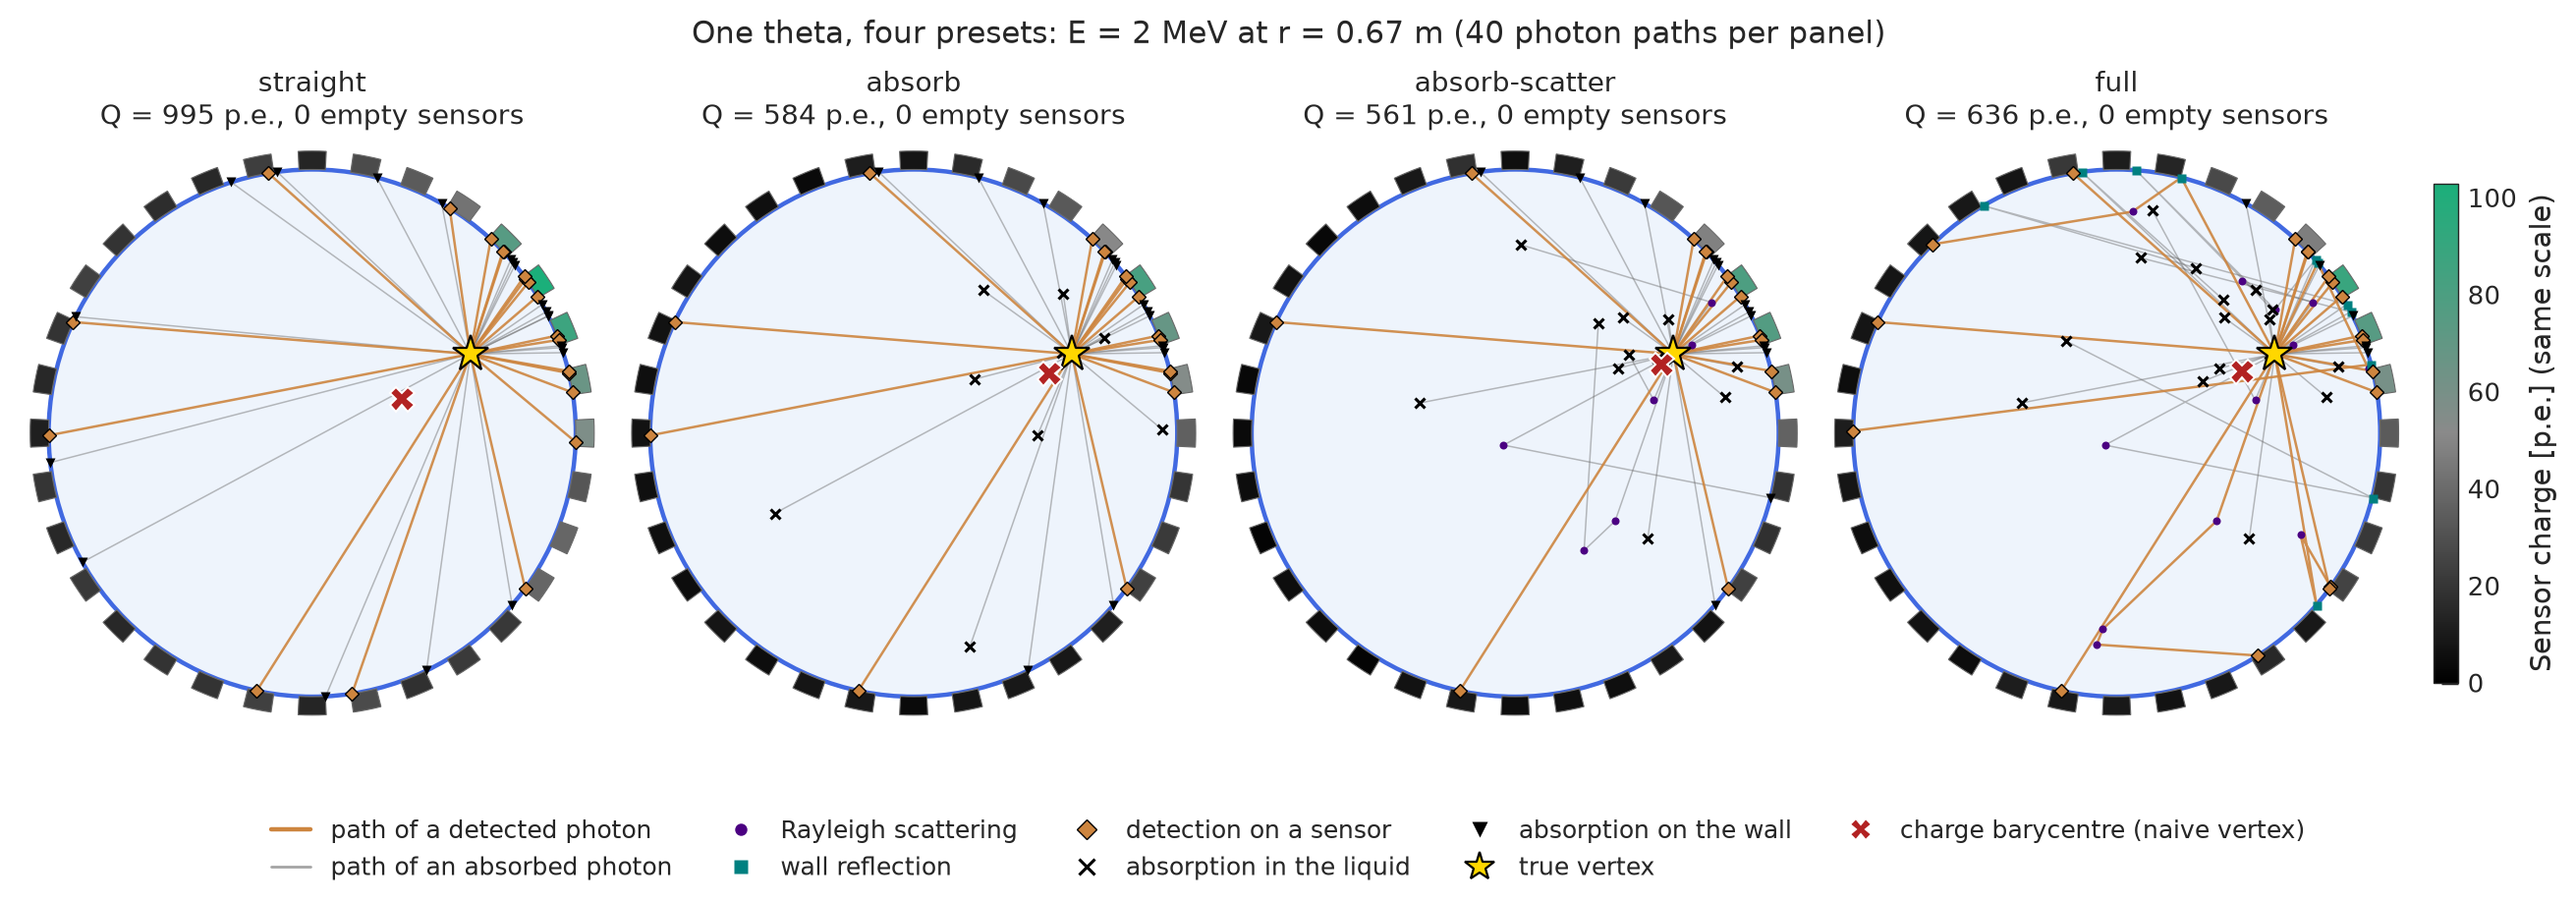

In [7]:
show("t4_4_presets")

- *Collected light:* Q = 1019.5 p.e. on average for straight light (spread 33.3 p.e. over the events), 597.4 p.e. with
  absorption, 567.7 p.e. with absorb-scatter, 627.6 p.e. in the full model (67.4 % of it direct, 23.0 % scattered,
  9.6 % reflected).
- *Straight light and the photocoverage:* from this vertex the sensor arcs together subtend 0.50930 of the full angle
  (the T3.2 formula), the photocoverage itself. That is no coincidence: for isotropic emission the density of wall
  hits is the mean of the disc's Poisson kernel and the uniform density, and the sum over M equally spaced sensors
  keeps only the azimuthal harmonics of order kM, so the collected fraction differs from the photocoverage by
  (1/π) Σ_k (r0/R)^(kM) sin(kMa/2R) cos(kM φ0)/k: −6e-7 here (r0 = 0.67 m, M = 32), but +0.0109 and −0.0109 at
  r0 = 0.9 m facing a sensor and a gap, the T3.2 results of 0.520 and 0.498 (`results/T4.json`,
  `T4.4_straight_light_harmonics`).
- *Pattern sharpness:* the ratio of the brightest to the dimmest mean sensor charge grows from 4.9 (straight) to 12.2
  (absorb) and 16.8 (absorb-scatter), and drops to 13.4 when reflections spread light around; the mean barycentre
  radius follows (true r = 0.67 m): 0.34 m for straight light, 0.54, 0.60 and 0.56 m for the other presets.

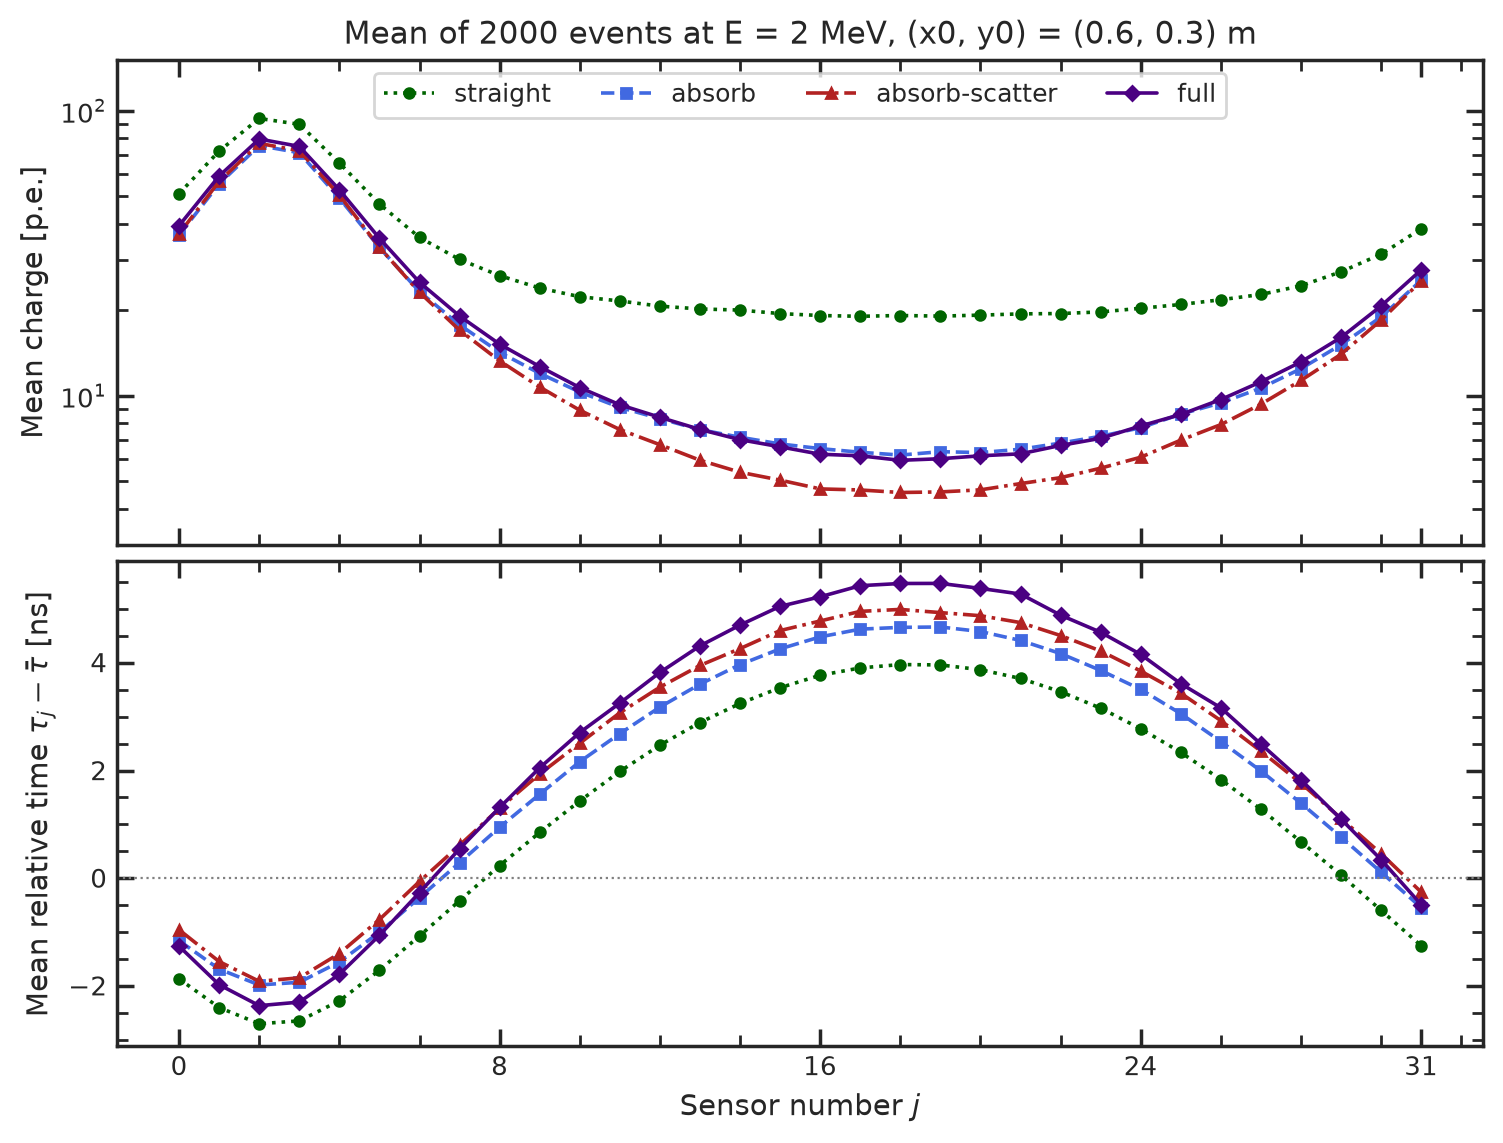

In [8]:
show("t4_4_profiles")

- *Times:* the vertical offsets of the relative-time profiles come from the reference τ̄ (the charge-weighted mean
  shifts when the near sensors gain weight); the late scattered and reflected light widens the range of the mean
  relative times from −2.7 ... +4.0 ns (straight) to −2.4 ... +5.5 ns (full).

*Figures:* `t4_4_presets` (one event per preset with 40 of its recorded photon paths, the same colour scale for all
four), `t4_4_profiles` (mean charge and mean relative time per sensor) (`task4_event_displays.py`). *Numbers:*
`results/T4.json` under `T4.4`.

## T4.5 Animation (bonus)

A 0.3 MeV flash at (0.25, 0.15) m emits 280 photons, all of them recorded (`save_tracks=1, track_photons=None`). Each
frame advances by 0.12 ns of physical time: a photon's position follows from the path length stored at every track
point (t = s / c_n), scatterings (indigo dots) and wall reflections (teal squares) appear when they happen, absorbed
photons turn grey, and detected ones stay peru (orange-brown) and light up their sensor on the scale of the final
charges.

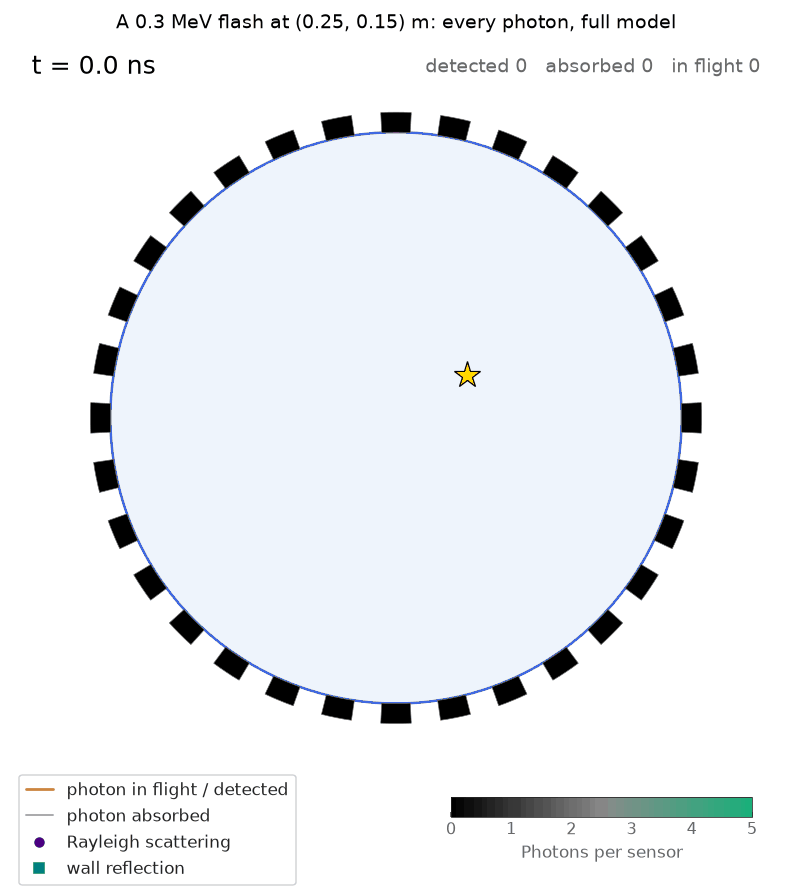

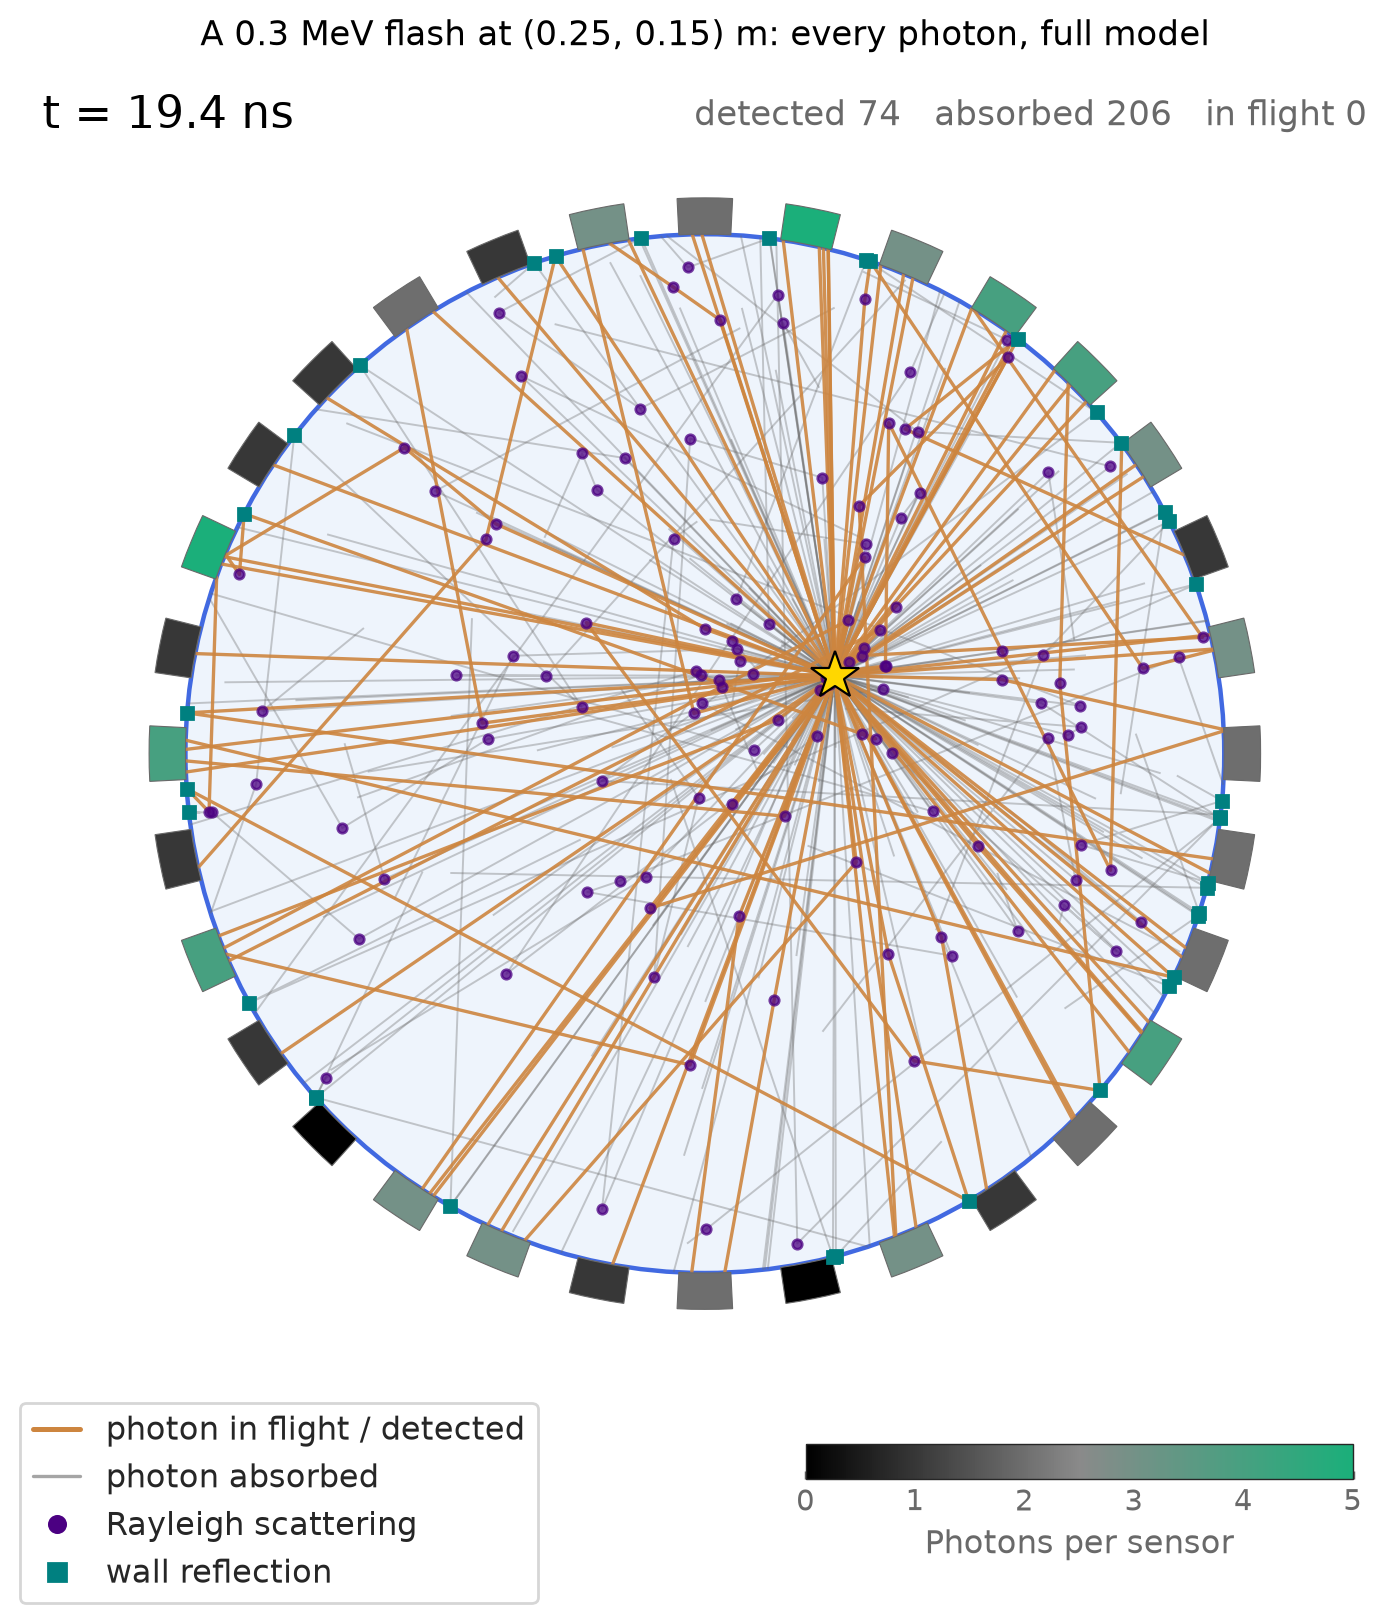

In [9]:
show("t4_5_photons", "t4_5_photons_frame")

**Details**

- *Timeline:* the first photon is detected 3.54 ns after the emission; half of the detected ones arrive by 5.69 ns;
  half of all photons have ended by 4.11 ns (most of them absorbed); the last one ends at 19.41 ns, leaving 74
  detected, 206 absorbed and none in flight.
- *File size, a practical point:* written the plain way of the TASKS.md hint (`FuncAnimation` saved with
  `writer="pillow"`), the same flash at 800 px with 203 frames is 8.9 MB, because every frame gets its own colour
  palette; one shared palette without dithering keeps the 163-frame GIF at 1.0 MB. The 8.9 MB were measured once with
  `python solutions/stage1_flash/task4_animation.py --compare-pillowwriter`, which `run_all.sh` does not run.
- The same code makes the README animation `docs/img/flash_photons.gif` (`make_readme_figures.py`).

*Output:* `figures/t4_5_photons.gif` (792 x 894 px, 163 frames, an 8.1 s loop, 1.0 MB) and its last frame
`t4_5_photons_frame` (`task4_animation.py`, helper `photon_animation.py`, a port of the seminar's
`flash_animation.py`). *Numbers:* `results/T4.json` under `T4.5`.